# Streaming-моніторинг платежів у Databricks · демо

Єдиний ноутбук, який запускаємо на презентації. Увесь код живе в ноутбуках `00`–`05`, тут лише виклики функцій.

| Частина | Що показуємо |
|---|---|
| 0 · Підготовка | запускається **до** презентації (≈15–20 хв) |
| 1 · Дані | що є в даних і що з цього випливає для моніторингу |
| 2 · Як це роблять batch | нічний звіт: проблему видно лише наступного ранку |
| 3 · Streaming-пайплайн | Bronze → Silver → Gold → Alerts: таблиці, колонки, розміри |
| 4 · Живий моніторинг | дані приходять щогодини, система сама піднімає тривогу |
| 5 · Batch проти streaming | обсяг роботи, швидкість, час виявлення, збережені гроші |
| 6 · Додатково | пізні дані, таблиця алертів |

In [0]:
%run ./00_config

In [0]:
%run ./01_data_prep

In [0]:
%run ./02_eda

In [0]:
%run ./03_pipeline

In [0]:
%run ./04_batch

In [0]:
%run ./05_alerting

## 0 · Підготовка

1. `prepare_data()`: нарізає CSV на погодинні файли й додає змодельований інцидент (≈ 3–5 хв, лише один раз).
2. `eda_prepare()`: Delta-таблиця для графіків EDA.
3. `run_batch_benchmark()`: кілька повних batch-перерахунків для порівняння (кілька хвилин, результат зберігається).
4. `run_nightly_batch()`: нічний batch-звіт за день інциденту (результат зберігається).
5. `reset_pipeline()` + `warm_up()`: прогнати через streaming усю історію до 14.09.2023, 08:00.



In [0]:
prepare_data()
eda_prepare()
run_batch_benchmark()
run_nightly_batch()
reset_pipeline()
warm_up()

✅ Готово за 366.0 с: 4 344 погодинних файлів, 685 447 рядків, 2023-04-01 … 2023-09-30.
   Змодельований інцидент: 141 рядків success -> fail (2023-09-14, 10:00-16:00, канал 6, картки USA).
✅ Створено workspace.payments_streaming.eda_payments: 685 447 рядків
Вимірюємо повний batch-перерахунок (це кілька хвилин) ...
  історія до 01.05.2023 00:00: 720 файлів, 95 874 рядків -> 23 с
  історія до 15.06.2023 00:00: 1 776 файлів, 249 997 рядків -> 31 с
  історія до 01.08.2023 00:00: 2 880 файлів, 424 550 рядків -> 39 с
  історія до 14.09.2023 08:00: 3 944 файлів, 635 488 рядків -> 53 с
🧹 Streaming-пайплайн скинуто: landing порожній, таблиці та checkpoints видалено.


26/11/25 21:19:58 Spark Server has not sent updates for Streaming Query 8558cd41-1de4-4ff0-aae1-b2c0b5c79a10 in 60 seconds, but the query is still active. Marking query as in-progress. Spark Session ID is 1bdfddea-535a-424d-ba71-7d5fcc9a7799. This is typically not a problem.
26/11/25 21:20:23 Spark Server has not sent updates for Streaming Query 8558cd41-1de4-4ff0-aae1-b2c0b5c79a10 in 60 seconds, but the query is still active. Marking query as in-progress. Spark Session ID is 1bdfddea-535a-424d-ba71-7d5fcc9a7799. This is typically not a problem.


✅ Історію завантажено: 3 944 погодинних файлів, 635 488 рядків, 1020 с. Змодельований час: 14.09.2023 08:00 .

## 1 · Дані: що ми моніторимо

Агреговані спроби оплати карткою за квітень–вересень 2023: статус, причина відмови, країна картки, канал, номер повторної спроби, діапазон суми.

In [0]:
eda_overview()

Рядків 685 447 агреговані спроби оплати Замовлень 826 063 з урахуванням count_orders Рівень схвалення 57.4% успішні / (успішні + відхилені) Період 01.04 – 30.09.2023 6 місяців Країн карток 205 Неіснуючі дати 7 587 напр. 31.09 → карантин

💡 Майже кожен другий платіж відхиляється: схвалюється лише 57.4%. 7 587 рядків мають дати, яких не існує, а 5 085 не мають даних про картку.

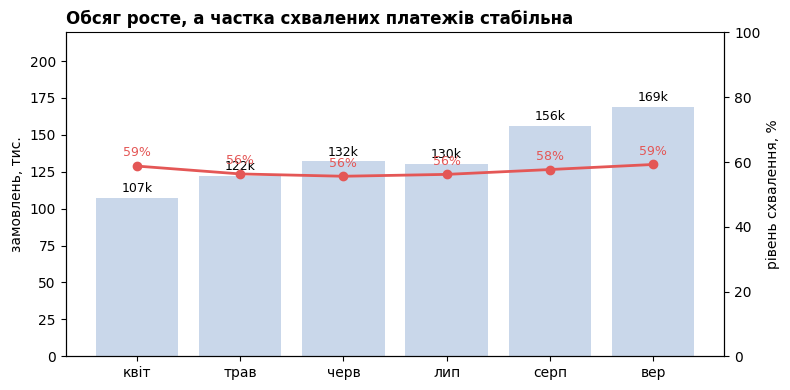

місяць,замовлень,схвалення_%
2023-04,107166,58.7
2023-05,122369,56.3
2023-06,131979,55.6
2023-07,130192,56.2
2023-08,156094,57.7
2023-09,168721,59.2


💡 За пів року обсяг зріс на 57%, а рівень схвалення тримається в межах 56–59%. Даних стає більше, тож перераховувати все щоразу буде все дорожче.

In [0]:
eda_monthly_trend()

### Чому платежі не проходять

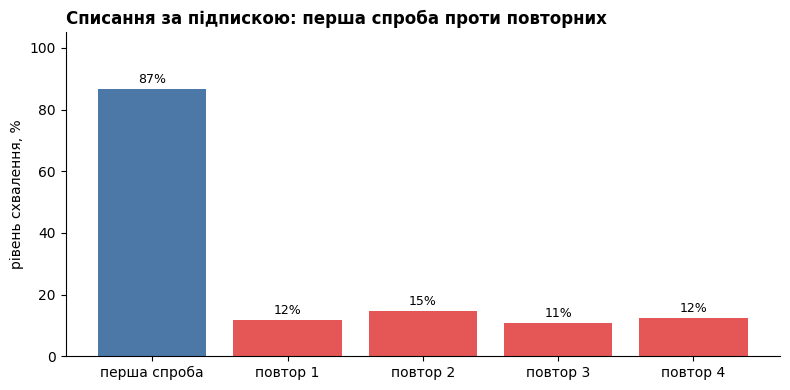

спроба,замовлень,схвалення_%
перша спроба,466796,86.6
повтор 1,54604,11.7
повтор 2,44713,14.7
повтор 3,34908,10.7
повтор 4,28104,12.3


💡 Перша спроба проходить у 87% випадків, повторні лише в 11–15%. Повтори становлять 20% усіх спроб, але дають лише 4% успішних платежів.

In [0]:
eda_retries()

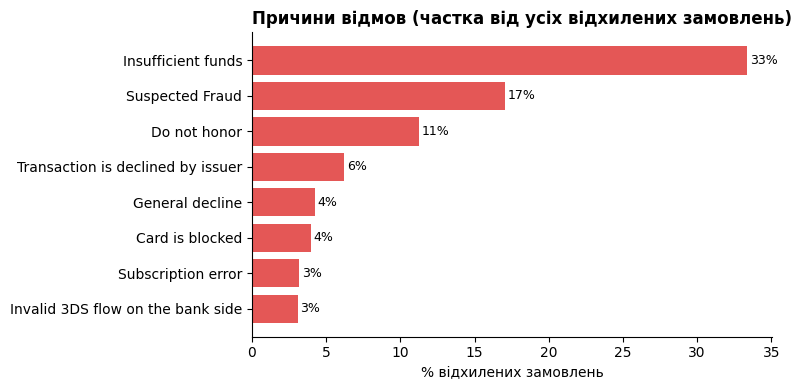

причина,відхилених замовлень,частка_%
Insufficient funds,117363,33.4
Suspected Fraud,59934,17.0
Do not honor,39575,11.3
Transaction is declined by issuer,21871,6.2
General decline,14855,4.2
Card is blocked,13937,4.0
Subscription error,11128,3.2
Invalid 3DS flow on the bank side,10810,3.1


💡 Три причини дають 62% усіх відмов: «Insufficient funds», «Suspected Fraud», «Do not honor». Більшість відмов приходить від банку клієнта, а не через технічні збої.

In [0]:
eda_decline_reasons()

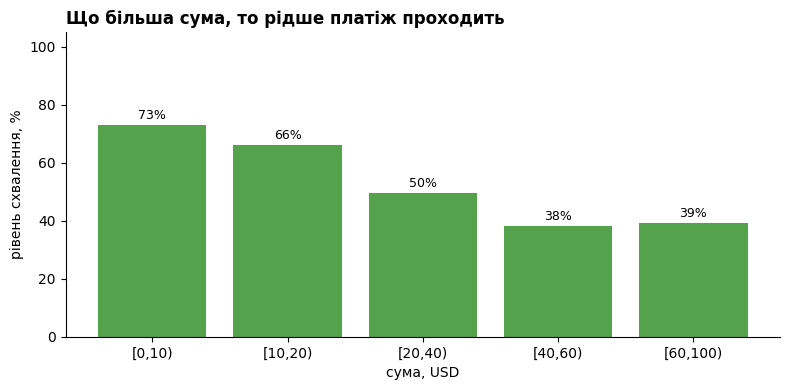

"сума, USD",замовлень,схвалення_%
"[0,10)",201322,73.0
"[10,20)",172532,66.2
"[20,40)",354351,49.6
"[40,60)",88970,38.2
"[60,100)",8497,39.3


💡 Платежі до $10 схвалюються в 73% випадків, а на $40–60 лише в 38%.

In [0]:
eda_amount()

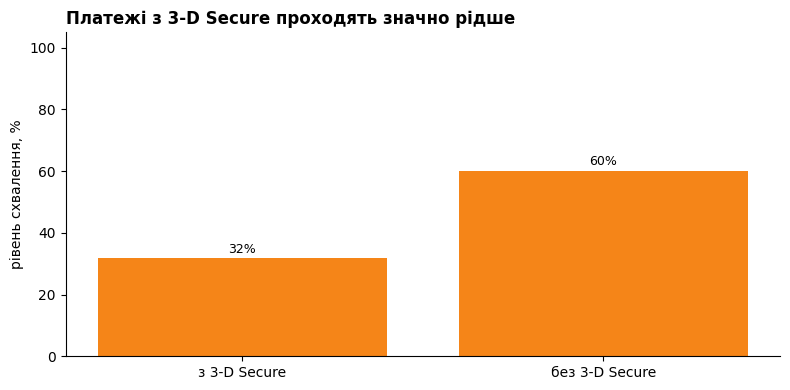

3-D Secure,замовлень,схвалення_%
без 3-D Secure,746931,60.1
з 3-D Secure,78970,31.7


💡 Через 3-D Secure проходить лише 10% замовлень, і вони найважчі. Обережно з висновками: 3DS, найімовірніше, вмикають для ризикованіших платежів, тож це зв'язок, а не доказ причини.

In [0]:
eda_3ds()

### Хто платить

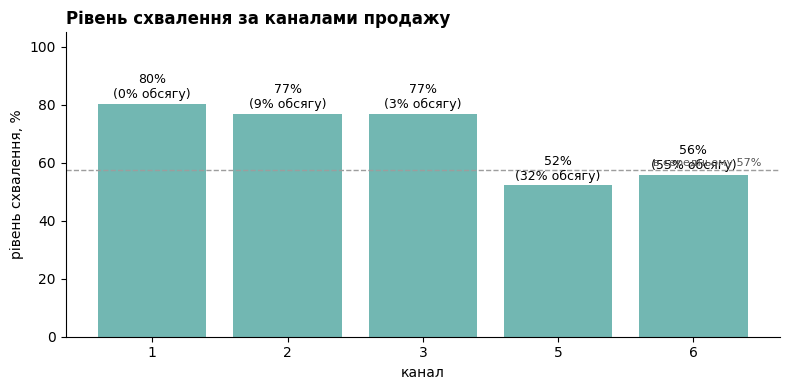

канал,замовлень,частка обсягу_%,схвалення_%
1,2314,0.3,80.4
2,77357,9.4,76.9
3,27114,3.3,76.8
5,266193,32.2,52.2
6,452923,54.8,55.9


💡 Два найбільші канали (6, 5) дають 87% обсягу, і саме в них схвалення найнижче. Тому моніторимо кожен канал окремо, а не одне загальне число.

In [0]:
eda_channels()

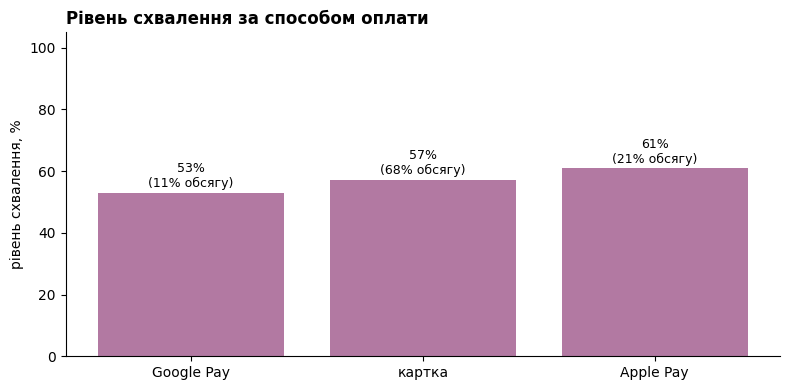

спосіб оплати,замовлень,частка обсягу_%,схвалення_%
Google Pay,93957,11.4,53.0
картка,557635,67.5,57.1
Apple Pay,174309,21.1,60.9


💡 Apple Pay проходить найкраще (61%), Google Pay найгірше (53%).

In [0]:
eda_payment_methods()

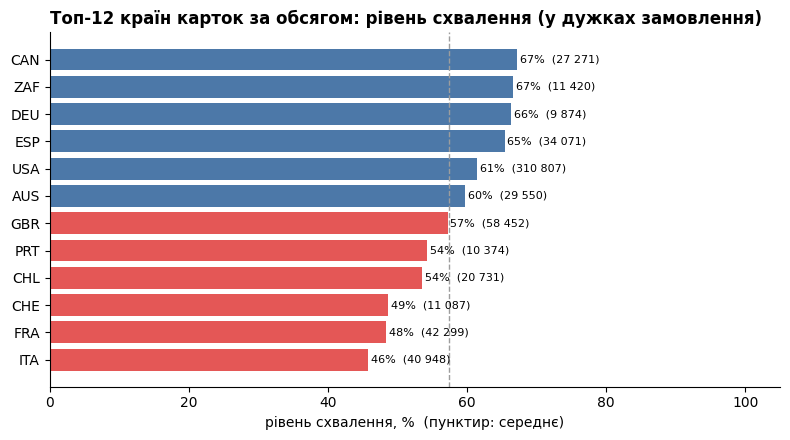

країна картки,замовлень,схвалення_%
USA,310807,61.4
GBR,58452,57.2
FRA,42299,48.4
ITA,40948,45.8
ESP,34071,65.4
AUS,29550,59.7
CAN,27271,67.2
CHL,20731,53.5
ZAF,11420,66.6
CHE,11087,48.7


💡 Різниця між країнами велика: від 46% (ITA) до 67% (CAN). США дають 51% обсягу цього топу, тому збій там б'є найсильніше.

In [0]:
eda_countries()

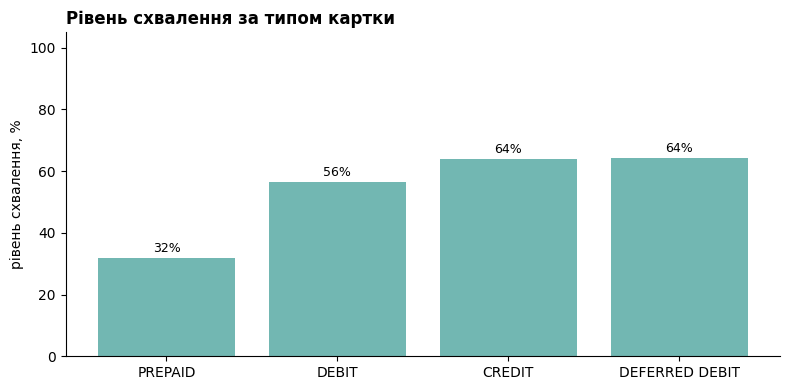

тип картки,замовлень,схвалення_%
PREPAID,37843,31.8
DEBIT,478990,56.4
CREDIT,293018,64.1
DEFERRED DEBIT,5388,64.4


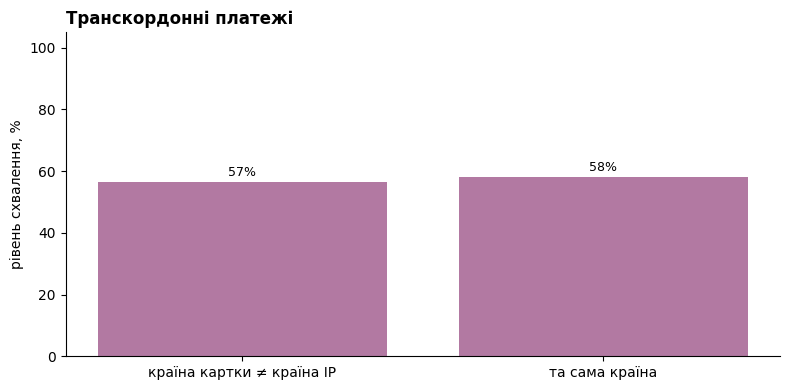

платіж,замовлень,схвалення_%
та сама країна,745745,58.2
країна картки ≠ країна IP,70447,56.6


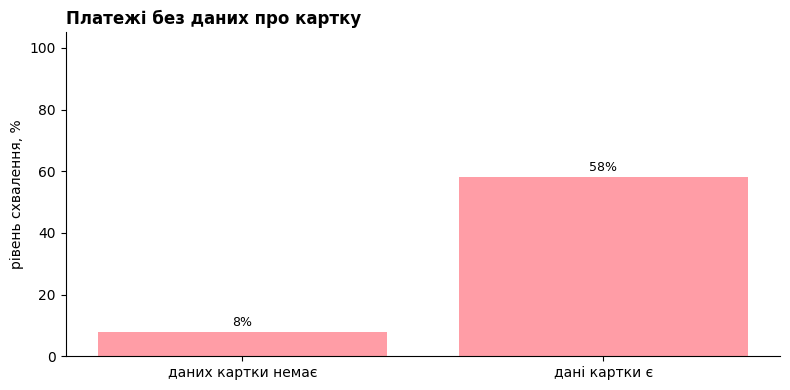

дані картки,замовлень,схвалення_%
дані картки є,815116,58.1
даних картки немає,10785,7.9


💡 Передплачені (prepaid) картки й транскордонні платежі відхиляються частіше, а платежі без даних картки майже ніколи не проходять (імовірно, картку так і не вдалося зчитати).

In [0]:
eda_quick_facts()

### Тижневий ритм: головне для логіки алертів

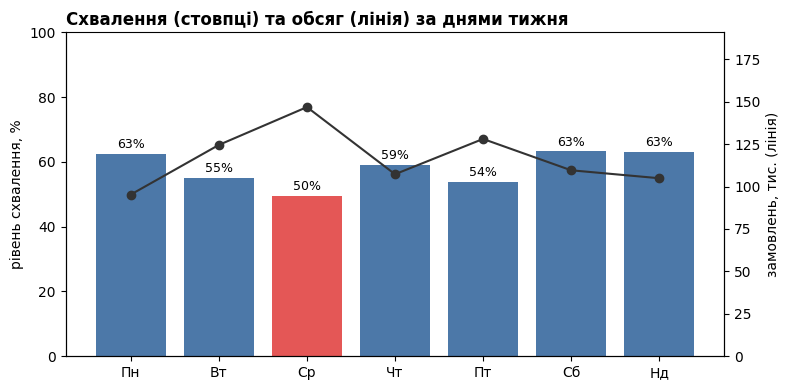

день тижня,замовлень,схвалення_%
Пн,95309,62.5
Вт,124538,55.0
Ср,146833,49.5
Чт,107265,59.0
Пт,128062,53.8
Сб,109598,63.3
Нд,104916,63.0


💡 У середу схвалюється лише 50% платежів, у вихідні понад 63%. Вівторок і середа мають найбільший обсяг (масові списання за підписками) і найнижче схвалення.

In [0]:
eda_weekday()

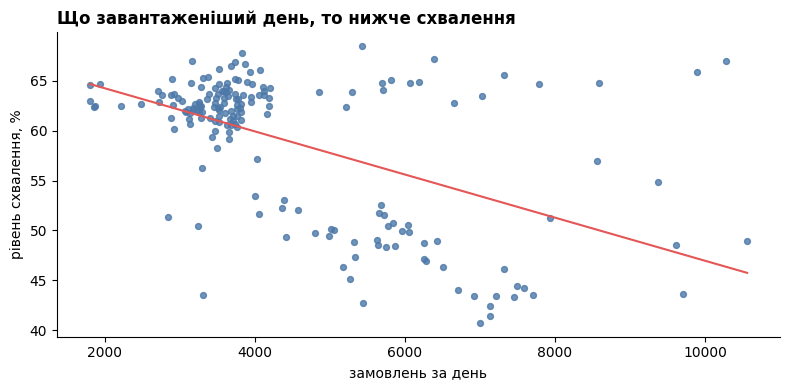

💡 Кореляція між обсягом за день і рівнем схвалення: -0.53. Висновок для моніторингу: порівнювати сьогодні з «останніми 7 днями» не можна, бо тоді щосереди будуть хибні тривоги. Наші алерти порівнюють ту саму годину того самого дня тижня за попередні 4 тижні.

In [0]:
eda_busy_days()

### Як історичні дані стають «потоком»

У CSV є лише дата, тому кожній події додано **синтетичний час доби**, а дані нарізано на **погодинні файли**.
Нова година даних = новий файл у папці `landing/`. Дати, денний і тижневий ритм справжні; розподіл подій усередині дня змодельований.

In [0]:
peek_staging()

Файл: payments_2023-04-01_00.csv


created_day,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,ip_country,invoice_number,retry_number,count_orders,count_emails,event_time
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[20,40)",success,null,null,2393,MASTERCARD,DEBIT,AUS,AUS,0,0,2,2,2023-04-01 00:02:20
2023-04-01 00:00:00.000000,6,first,card,null,FALSE,"[20,40)",success,null,null,7524,VISA,CREDIT,USA,USA,0,0,1,1,2023-04-01 00:05:23
2023-04-01 00:00:00.000000,5,first,google-pay,null,FALSE,"[20,40)",fail,3.02,Insufficient funds,7962,VISA,DEBIT,IRL,IRL,null,no_subscription,1,1,2023-04-01 00:05:24
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[0,10)",fail,0.01,General decline,6745,MASTERCARD,DEBIT,CZE,CZE,null,no_subscription,1,1,2023-04-01 00:06:07
2023-04-01 00:00:00.000000,2,token,card,recurring,FALSE,"[10,20)",success,null,null,7843,VISA,DEBIT,CAN,CAN,61,0,1,1,2023-04-01 00:06:40
2023-04-01 00:00:00.000000,5,token,card,recurring,FALSE,"[10,20)",fail,3.02,Insufficient funds,6535,MASTERCARD,CREDIT,CHL,CHL,1,1,1,1,2023-04-01 00:08:48
2023-04-01 00:00:00.000000,6,first,apple-pay,null,FALSE,"[40,60)",success,null,null,4043,MASTERCARD,CREDIT,USA,USA,0,0,5,5,2023-04-01 00:09:57
2023-04-01 00:00:00.000000,2,token,card,recurring,FALSE,"[0,10)",success,null,null,8541,MASTERCARD,DEBIT,SGP,SGP,47,0,1,1,2023-04-01 00:10:29
2023-04-01 00:00:00.000000,6,first,card,null,TRUE,"[20,40)",fail,3.10,Suspected Fraud,3623,VISA,CREDIT,USA,USA,null,no_subscription,3,1,2023-04-01 00:14:31
2023-04-01 00:00:00.000000,3,token,card,recurring,FALSE,"[0,10)",success,null,null,6797,VISA,DEBIT,USA,USA,45,0,1,1,2023-04-01 00:14:39


## 2 · Як це роблять batch: нічний звіт

**Сценарій.** Четвер, 14.09.2023. О 10:00 у каналі 6 частина платежів карток із США починає відхилятися з кодом «Do not honor»
(так виглядає, наприклад, збій у еквайра). Збій триває до 16:00. *Інцидент змодельований, решта даних справжня.*

Типова компанія без streaming рахує звіт **раз на добу**: о 06:00 batch-задача перечитує всю історію і показує вчорашній день.

In [0]:
show_nightly_report(run_nightly_batch())

(результат нічного запуску взято з кешу: 52 с, 3 960 файлів)


сегмент,замовлень,схвалення,норма,падіння
канал 6 · USA,1 687,56.3%,72.7%,−16.4 п.п.


канал,країна,замовлень,схвалення_%,норма_%,падіння_пп,z_score
6,USA,1687,56.3,72.7,16.4,-15.1


**А якщо запускати batch частіше, наприклад щогодини?** Кожен запуск усе одно перечитує всю історію, а вона росте.

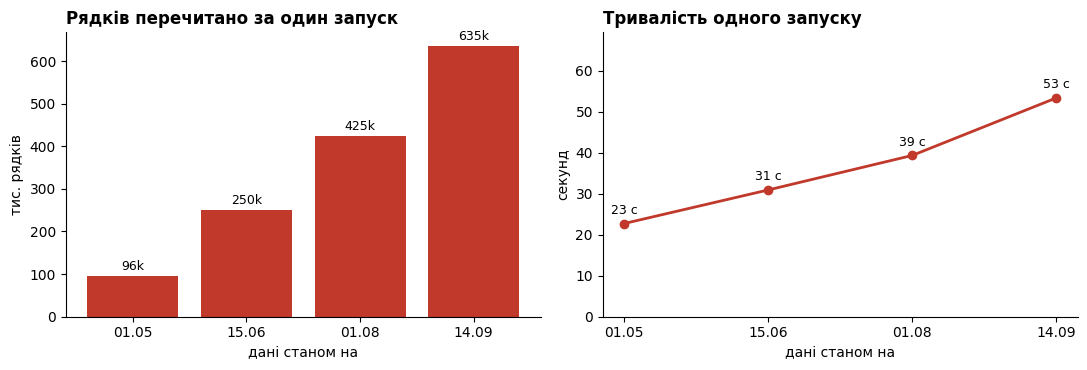

дані станом на,файлів,рядків,секунд
01.05.2023 00:00,720,95874,22.7
15.06.2023 00:00,1776,249997,30.9
01.08.2023 00:00,2880,424550,39.3
14.09.2023 08:00,3944,635488,53.3


💡 Кожен batch-запуск перечитує всю історію. Щоб бачити дані свіжістю в 1 годину, його довелося б запускати 24 рази на добу: це 15 251 712 перечитаних рядків і близько 21 хв обчислень щодня, і з кожним днем більше.

In [0]:
plot_batch_cost()

## 3 · Streaming-пайплайн

```
landing/ ──► BRONZE ──► SILVER ──► GOLD ──► ALERTS
              сирі       чисті     схвалення   незвичні
              дані       дані      по годинах  падіння
                         └─► QUARANTINE
```

Ключові рядки коду (повністю в `03_pipeline`):

```python
spark.readStream.format("cloudFiles")          # Auto Loader: лише нові файли
  ...writeStream.foreachBatch(_ingest_batch)   # Bronze + Silver + Quarantine
  .trigger(availableNow=True)                  # обробити все нове і зупинитися

spark.readStream.table(silver)
  .withWatermark("event_time", "2 hours")      # що пізніше, ігноруємо
  .groupBy(window("event_time", "1 hour"), "channel_id", "card_country_grp")
  .writeStream.outputMode("update")            # оновлюємо лише змінені вікна (MERGE у Gold)
```

Історія до 14.09.2023, 08:00 уже пройшла через пайплайн (частина 0). Ось як він виглядає зараз:

In [0]:
show_pipeline_overview()

Landing файлів: 3 944 розмір: 88.4 MB погодинні CSV, які «прийшли» ➜ Bronze рядків: 635 488 колонок: 23 розмір: 5.8 MB · файлів: 3 Сирі дані як є, усі колонки текстом + звідки й коли прийшли ➜ Silver рядків: 629 615 колонок: 24 розмір: 5.9 MB · файлів: 3 Чисті дані з правильними типами + допоміжні колонки ➜ Gold рядків: 103 850 колонок: 8 розмір: 0.7 MB · файлів: 1 Замовлення, успішні, відхилені й схвалення за кожну годину й сегмент ➜ Alerts рядків: 0 колонок: 15 розмір: 0.0 MB · файлів: 0 Вікна, де схвалення незвично впало ↳ Quarantine рядків: 5 873 колонок: 24 розмір: 0.1 MB · файлів: 2 Биті рядки з оригінальними значеннями і причиною dq_reason

шар,таблиця / шлях,рядків,колонок,розмір_MB,файлів
Landing,/Volumes/workspace/payments_streaming/data/landing,null,null,88.4,3944
Bronze,workspace.payments_streaming.bronze_payments,635488.0,23.0,5.8,3
Silver,workspace.payments_streaming.silver_payments,629615.0,24.0,5.9,3
Quarantine,workspace.payments_streaming.quarantine_payments,5873.0,24.0,0.1,2
Gold,workspace.payments_streaming.gold_hourly,103850.0,8.0,0.7,1
Alerts,workspace.payments_streaming.alerts,0.0,15.0,0.0,0


In [0]:
show_layer("bronze")

Bronze · workspace.payments_streaming.bronze_payments Сирі дані як є, усі колонки текстом + звідки й коли прийшли

колонка,тип
created_day,string
channel_id,string
order_type,string
payment_source,string
merchant_token_type,string
is_secured,string
bin_amount_usd,string
status,string
error_code,string
error_message,string


created_day,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,ip_country,invoice_number,retry_number,count_orders,count_emails,event_time,_rescued_data,_source_file,_ingested_at
2023-09-06 00:00:00.000000,5,first,card,null,TRUE,"[20,40)",fail,5.01,3D secure verification failed,4618,MASTERCARD,CREDIT,ITA,ITA,null,no_subscription,1,1,2023-09-06 20:00:02,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06 00:00:00.000000,6,token,card,recurring,FALSE,"[60,100)",success,null,null,4618,MASTERCARD,DEBIT,ITA,ITA,1,0,1,1,2023-09-06 20:00:10,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06 00:00:00.000000,6,token,card,1-click,FALSE,"[0,10)",success,null,null,6696,VISA,DEBIT,QAT,QAT,0,0,1,1,2023-09-06 20:00:18,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06 00:00:00.000000,6,first,google-pay,null,FALSE,"[0,10)",success,null,null,4618,MASTERCARD,DEBIT,ITA,ITA,0,0,1,1,2023-09-06 20:00:20,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06 00:00:00.000000,5,token,card,recurring,FALSE,"[20,40)",fail,3.02,Insufficient funds,7098,VISA,DEBIT,URY,URY,2,2,1,1,2023-09-06 20:00:22,null,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z


In [0]:
show_layer("silver")

Silver · workspace.payments_streaming.silver_payments Чисті дані з правильними типами + допоміжні колонки

колонка,тип
event_time,timestamp
channel_id,string
order_type,string
payment_source,string
merchant_token_type,string
is_secured,boolean
bin_amount_usd,string
status,string
error_code,string
error_message,string


event_time,channel_id,order_type,payment_source,merchant_token_type,is_secured,bin_amount_usd,status,error_code,error_message,bank_issuer,card_brand,card_type,card_country,card_country_grp,ip_country,country_mismatch,is_subscription_charge,retry_count,count_orders,count_emails,created_day,_source_file,_ingested_at
2023-09-06T20:00:02.000Z,5,first,card,null,true,"[20,40)",fail,5.01,3D secure verification failed,4618,MASTERCARD,CREDIT,ITA,ITA,ITA,false,false,null,1,1,2023-09-06 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06T20:00:10.000Z,6,token,card,recurring,false,"[60,100)",success,null,null,4618,MASTERCARD,DEBIT,ITA,ITA,ITA,false,true,0,1,1,2023-09-06 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06T20:00:18.000Z,6,token,card,1-click,false,"[0,10)",success,null,null,6696,VISA,DEBIT,QAT,OTHER,QAT,false,true,0,1,1,2023-09-06 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06T20:00:20.000Z,6,first,google-pay,null,false,"[0,10)",success,null,null,4618,MASTERCARD,DEBIT,ITA,ITA,ITA,false,true,0,1,1,2023-09-06 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z
2023-09-06T20:00:22.000Z,5,token,card,recurring,false,"[20,40)",fail,3.02,Insufficient funds,7098,VISA,DEBIT,URY,OTHER,URY,false,true,2,1,1,2023-09-06 00:00:00.000000,/Volumes/workspace/payments_streaming/data/landing/payments_2023-09-06_20.csv,2026-11-25T22:31:31.121Z


In [0]:
show_layer("gold")

Gold · workspace.payments_streaming.gold_hourly Замовлення, успішні, відхилені й схвалення за кожну годину й сегмент

колонка,тип
window_start,timestamp
window_end,timestamp
channel_id,string
card_country_grp,string
total_orders,bigint
success_orders,bigint
fail_orders,bigint
approval_rate,double


window_start,window_end,channel_id,card_country_grp,total_orders,success_orders,fail_orders,approval_rate
2023-09-06T20:00:00.000Z,2023-09-06T21:00:00.000Z,2,CHL,5,4,1,0.8
2023-09-06T13:00:00.000Z,2023-09-06T14:00:00.000Z,6,GBR,44,29,15,0.6590909090909091
2023-09-13T21:00:00.000Z,2023-09-13T22:00:00.000Z,2,ESP,2,2,0,1.0
2023-08-30T19:00:00.000Z,2023-08-30T20:00:00.000Z,5,GBR,8,7,1,0.875
2023-09-06T18:00:00.000Z,2023-09-06T19:00:00.000Z,1,OTHER,2,1,1,0.5


**Якість даних.** Рядки з датами, яких не існує (31 квітня, 31 червня, 31 вересня), не ламають потік: вони йдуть у карантин з оригінальними значеннями.

In [0]:
show_quarantine()

причина,рядків,замовлень
invalid_event_time,5865,7088
success_with_error_code,8,8


created_day,event_time,status,count_orders,dq_reason,_source_file
2023-06-31 00:00:00.000000,2023-06-31 06:00:20,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:01:27,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:01:35,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:03:00,fail,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv
2023-06-31 00:00:00.000000,2023-06-31 06:03:03,success,1,invalid_event_time,/Volumes/workspace/payments_streaming/data/landing/payments_2023-06-30_06.csv


**Це справді streaming?** Запустимо ті самі запити ще раз, без нових файлів.

In [0]:
rerun_without_new_data()

🔁 Повторний запуск без нових файлів: ingest прочитав 0 рядків, Gold 0 (10.3 с). Checkpoint пам'ятає, що вже оброблено. Batch на цьому місці перечитав би всю історію.

## 4 · Живий моніторинг

Зараз 14.09.2023, 08:00. Щогодини приходить нова година даних, пайплайн її обробляє, і система перевіряє кожен сегмент
(канал × країна картки) проти норми для цієї години цього дня тижня.

In [0]:
live_monitoring(hours=4)

▶️ Моніторинг запущено. Зараз 14.09.2023 08:00 , оновлення щогодини, сегменти: channel_id × card_country_grp.

🕐 14.09.2023 09:00 · прийшла година 08:00–09:00: 220 рядків · обробка 43.1 с · state: 82 рядків · канал 6 · картки USA: 73% · ✅ відхилень немає

🕐 14.09.2023 10:00 · прийшла година 09:00–10:00: 251 рядків · обробка 48.0 с · state: 88 рядків · канал 6 · картки USA: 71% · ✅ відхилень немає

🕐 14.09.2023 11:00 · прийшла година 10:00–11:00: 249 рядків · обробка 52.4 с · state: 90 рядків · канал 6 · картки USA: 25% · 🚨 нових алертів: 1

🚨 P1 · ALERT · ALR-20230914-10-6-USA 
 спрацював 14.09.2023 о 11:00 
 
 Різко впав рівень схвалення платежів 
 Сегмент: канал 6 · картки USA · година 10:00–11:00 
 
 Схвалення зараз 25% 
 Норма для цієї години 75% 
 Падіння −50 п.п. 
 Замовлень за годину 92 
 Втрачено платежів (оцінка) 46 
 Під загрозою ≈ $1 255 
 
 
 Головні причини відмов: Do not honor — 77% відмов Insufficient funds — 16% відмов Suspected Fraud — 8% відмов 
 Що робити зараз: 
 Перевірити статус еквайра та процесингу для цього сегмента. 
 Якщо збій на боці еквайра чи банку, перемкнути маршрутизацію на резервного еквайра. 
 Призупинити автоматичні повторні списання (retries) для сегмента: зараз вони лише додадуть відмов. 
 Повідомити account-менеджера мерчанта каналу 6. 
 
 
 📣 Сповіщено: #payments-oncall (Slack) · черговий інженер (PagerDuty) · відкрито інцидент INC-0914-6USA 
   (симуляція) · z-score = -11.0

🕐 14.09.2023 12:00 · прийшла година 11:00–12:00: 271 рядків · обробка 61.4 с · state: 91 рядків · канал 6 · картки USA: 17% · 🚨 нових алертів: 1

🔁 Інцидент триває (канал 6 · картки USA) · 11:00–12:00: схвалення 17% (норма 71%), ще ≈ 49 втрачених платежів. Оновлення додано в інцидент INC-0914-6USA, повторних сповіщень не надсилаємо.

змодельований час,файл,рядків прочитано,секунд,state (рядків),"схвалення сегмента, %",нових алертів
14.09 09:00,payments_2023-09-14_08.csv,220,43.1,82,72.5,0
14.09 10:00,payments_2023-09-14_09.csv,251,48.0,88,70.7,0
14.09 11:00,payments_2023-09-14_10.csv,249,52.4,90,25.0,1
14.09 12:00,payments_2023-09-14_11.csv,271,61.4,91,16.7,1


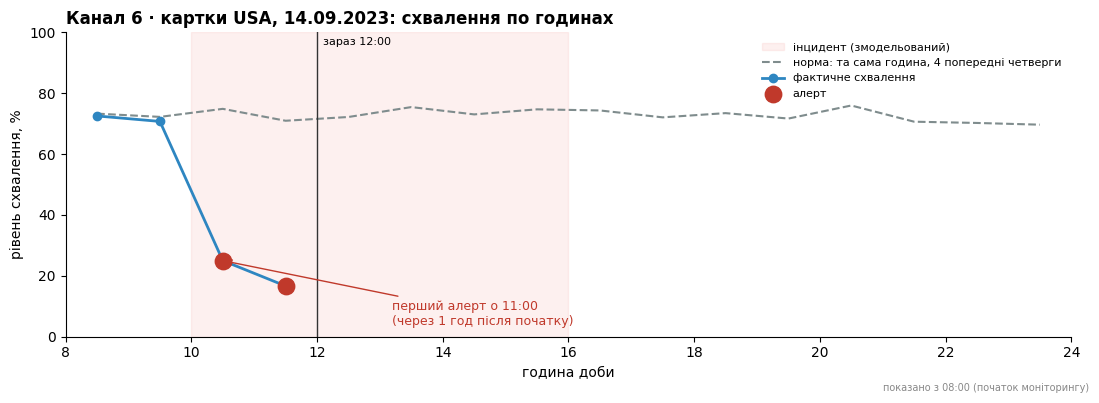

година,замовлень,успішних,схвалення_%,норма_%,падіння_пп,z_score,алерт
08:00–09:00,91,66,72.5,73.3,0.8,-0.2,
09:00–10:00,82,58,70.7,72.2,1.5,-0.3,
10:00–11:00,92,23,25.0,74.9,49.9,-11.0,P1
11:00–12:00,90,15,16.7,71.0,54.3,-11.3,P1


In [0]:
plot_incident_day()

Перемотаємо час до ранку наступного дня (саме тоді прийшов би нічний batch-звіт):

In [0]:
catch_up()

⏩ Перемотали до 15.09.2023 08:00 : оброблено 20 год, нових алертів: 4 (продовження того самого інциденту).

alert_id,window_start,approval_pct,baseline_pct,drop_pp,lost_orders_est,severity
ALR-20230914-12-6-USA,2023-09-14T12:00:00.000Z,22.5,72.2,49.7,44,P1
ALR-20230914-13-6-USA,2023-09-14T13:00:00.000Z,43.9,75.4,31.5,34,P1
ALR-20230914-14-6-USA,2023-09-14T14:00:00.000Z,35.9,73.0,37.1,29,P1
ALR-20230914-15-6-USA,2023-09-14T15:00:00.000Z,34.3,74.7,40.4,41,P1


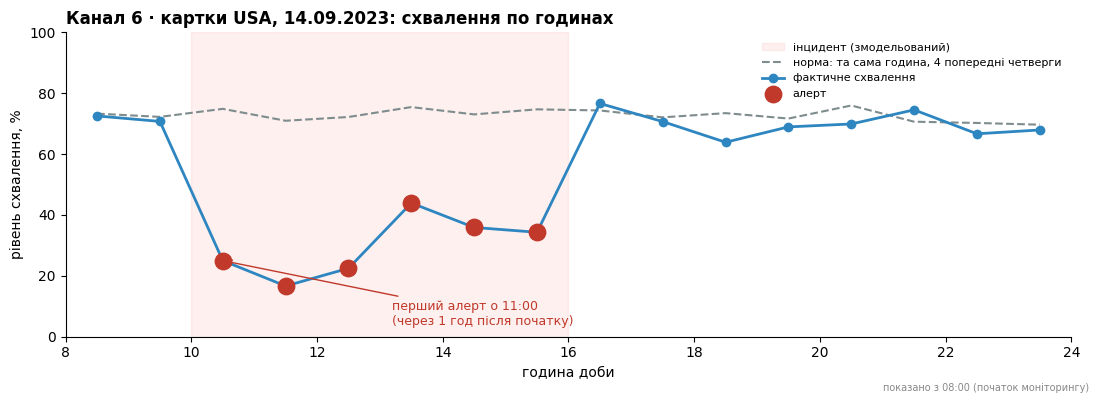

година,замовлень,успішних,схвалення_%,норма_%,падіння_пп,z_score,алерт
08:00–09:00,91,66,72.5,73.3,0.8,-0.2,
09:00–10:00,82,58,70.7,72.2,1.5,-0.3,
10:00–11:00,92,23,25.0,74.9,49.9,-11.0,P1
11:00–12:00,90,15,16.7,71.0,54.3,-11.3,P1
12:00–13:00,89,20,22.5,72.2,49.7,-10.5,P1
13:00–14:00,107,47,43.9,75.4,31.5,-7.6,P1
14:00–15:00,78,28,35.9,73.0,37.1,-7.4,P1
15:00–16:00,102,35,34.3,74.7,40.4,-9.4,P1
16:00–17:00,107,82,76.6,74.3,-2.3,0.5,
17:00–18:00,133,94,70.7,72.1,1.4,-0.4,


In [0]:
plot_incident_day()

## 5 · Batch проти streaming

### Скільки роботи робить кожне оновлення

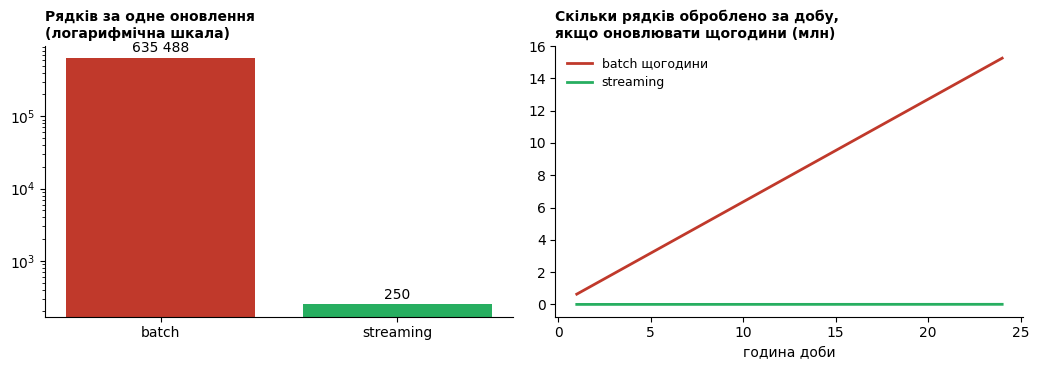

показник,batch (повний перерахунок),streaming (лише нове)
файлів за одне оновлення,3 944,1
рядків за одне оновлення,635 488,250
секунд за одне оновлення,53,50
рядків за добу (оновлення щогодини),15 251 712,6 000
"state у пам'яті, рядків",—,72


Batch: рядків за оновлення 635 488 перечитує всю історію Streaming: рядків за оновлення 250 лише нова година У скільки разів менше даних ×2 542 на кожному оновленні

ℹ️ Чесно про секунди: зараз історія ще мала (≈ 635 тис. рядків), тому час практично однаковий (див. таблицю). Кожне streaming-оновлення витрачає десятки секунд на запуск двох запитів (фіксовані витрати serverless), а сама обробка нової години займає лічені секунди. Різниця в обсязі роботи уже величезна, а в секундах вона проявляється з ростом історії (графік нижче).

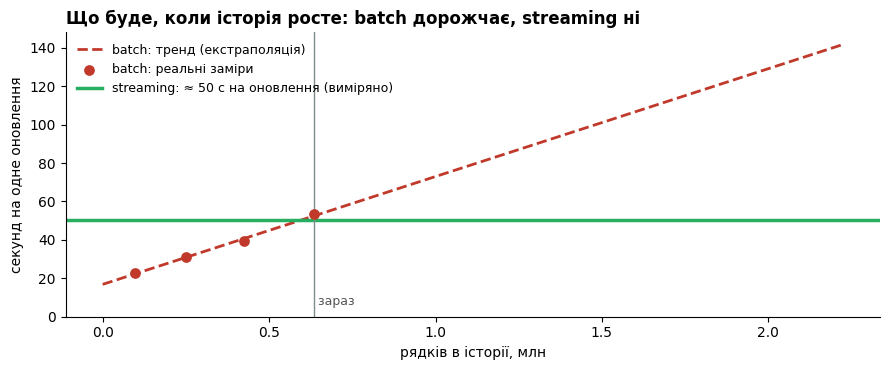

📈 Лінія batch — це продовження виміряного тренду (+5.6 с на кожні 100 тис. рядків), а не окремий вимір. При 2.2 млн рядків (≈ у 3.5 раза більше за поточне) повний перерахунок тривав би близько 142 с , а streaming-оновлення й далі обробляє лише нову годину.

In [0]:
plot_batch_vs_streaming()

In [0]:
show_processing_diagram()

Що відбувається всередині за одне оновлення 
 Batch · читає всі файли з початку історії, чистить і агрегує все заново 635 488 рядків 
 Streaming: нові дані · Auto Loader бере лише файли, яких ще не бачив (checkpoint) 250 рядків 
 Streaming: state у пам'яті · проміжні суми відкритих годинних вікон; старі вікна прибирає watermark 72 рядків

### Коли ми дізнаємося про проблему і скільки це коштує

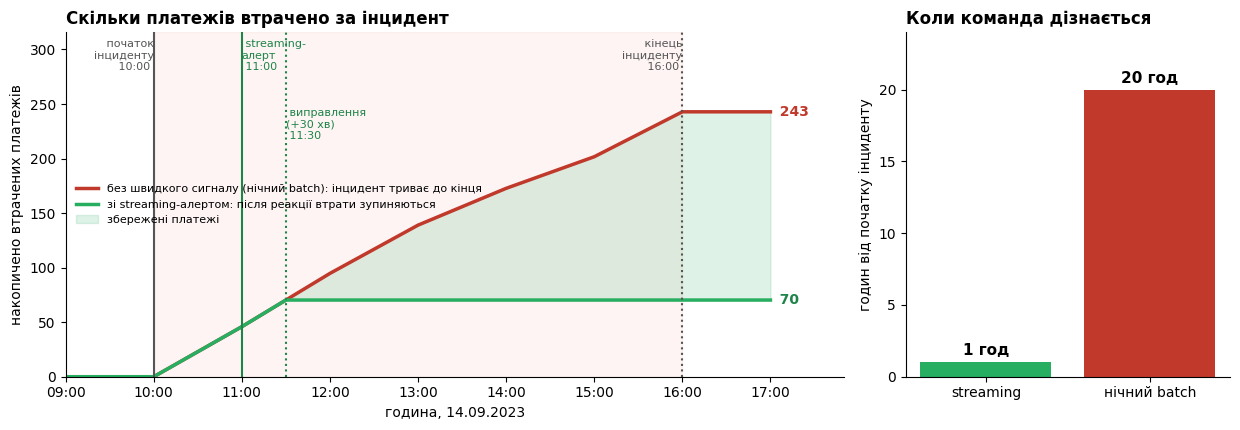

подія,час,годин від початку
початок інциденту,14.09.2023 10:00,0.0
streaming: перший алерт,14.09.2023 11:00,1.0
streaming: виправлення (+30 хв),14.09.2023 11:30,1.5
кінець інциденту (сам),14.09.2023 16:00,6.0
batch: звіт готовий,15.09.2023 06:00,20.0
batch: виправлення (+30 хв),15.09.2023 06:30,20.5


In [0]:
show_detection_timeline()

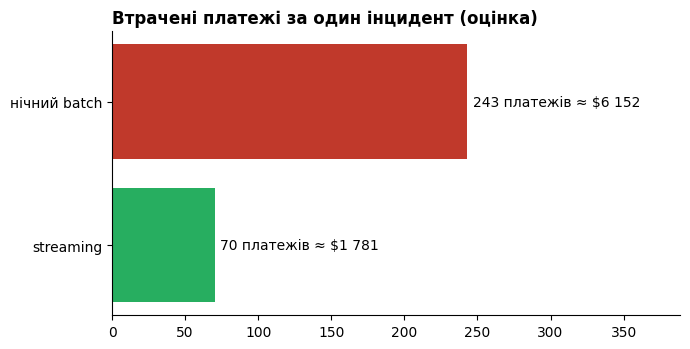

підхід,сигнал,затримка_год,виправлення,втрачено_платежів,втрачено_USD
streaming (годинні вікна),14.09 11:00,1.0,14.09 11:30,70,1781
нічний batch-звіт,15.09 06:00,20.0,15.09 06:30,243,6152
різниця (збережено),,19.0,,173,4372


Streaming: сигнал через 1 год о 11:00 того ж дня Batch: сигнал через 20 год о 06:00 наступного дня Збережено платежів 173 71% втрат вдалося б уникнути Збережено грошей ≈ $4 372 середній чек ≈ $25

ℹ️ Як рахуємо: втрата за годину = замовлення × норма схвалення − фактично успішні. Припускаємо, що після сигналу команда за 30 хв перемикає трафік на резервного еквайра. Batch-звіт приходить, коли інцидент уже скінчився, тож усі втрати вже сталися. Це оцінка на змодельованому інциденті, а не фактичні гроші компанії.

In [0]:
show_business_impact()

### Висновки

* **Streaming обробляє лише нове**: checkpoint пам'ятає оброблені файли, state зберігає відкриті вікна, watermark відсікає запізнілі дані.
  Обсяг роботи на одне оновлення не росте з історією, а в batch росте.
* **Проблему видно за годину, а не наступного ранку**, тож команда встигає зреагувати, поки інцидент ще триває.
* **Чесні обмеження**: час доби змодельований, дані «приходять» цілими годинами, інцидент штучний, а `availableNow`
  запускається вручну (на serverless немає постійно ввімкнених тригерів). На кластері той самий код працює безперервно, змінюється лише тригер.
* **Застосування до інших даних**: змінити `CONFIG` у `00_config`, підготовку файлів у `01_data_prep` і правила якості в `transform_silver`.